# 2. Synthetic control: computer systems design industry

**Question:** Did the computer systems design industry fall below a synthetic twin built from low-exposure industries?

**How to use:** Run All. It shows the saved results in seconds. To recompute from the data, set `RUN = True` (about 5 minutes; needs the raw data in `data/raw/`, which isn't in the public repo; see the README).

In [1]:
from _nb import *

RUN = False
if RUN:
    run("synth_industry")
    run("synth_variants")


## How it works

- **Data:** CES payroll employment (big samples), quarterly, 1990–2026. Pandemic quarters left out of the fit.
- **Five variants** (ridge penalty, growth rates, wider donor pool…). **One was picked by a rule written before seeing
  results:** lowest hold-out error among variants that spread weight over at least 4 donors.
- **Inference:** placebo-in-space. Rerun with every donor as if it were "treated"; tech's gap has to stand out.

## Results

In [2]:
v = results("synth_variants")
t = pd.DataFrame(v["variants"]).set_index("variant")
t = t[["holdout_error_2018_19", "effective_donors", "gap_2022", "gap_2026", "p_value"]]
print("Chosen by the pre-set rule:", v["chosen"])
t.style.format({"holdout_error_2018_19": "{:.1%}", "gap_2022": "{:+.1%}", "gap_2026": "{:+.1%}"})

Chosen by the pre-set rule: E. wider pool + ridge


,holdout_error_2018_19,effective_donors,gap_2022,gap_2026,p_value
variant,,,,,
A. baseline,4.9%,2.000000,+0.2%,-16.2%,0.200000
B. ridge,1.5%,3.300000,-0.9%,-13.2%,0.270000
C. growth (yoy),2.3%,6.700000,-0.6%,-24.4%,0.090000
D. wider pool (<75th pct),3.4%,3.300000,-0.3%,-15.0%,0.290000
E. wider pool + ridge,0.6%,4.300000,+0.2%,-13.0%,0.290000


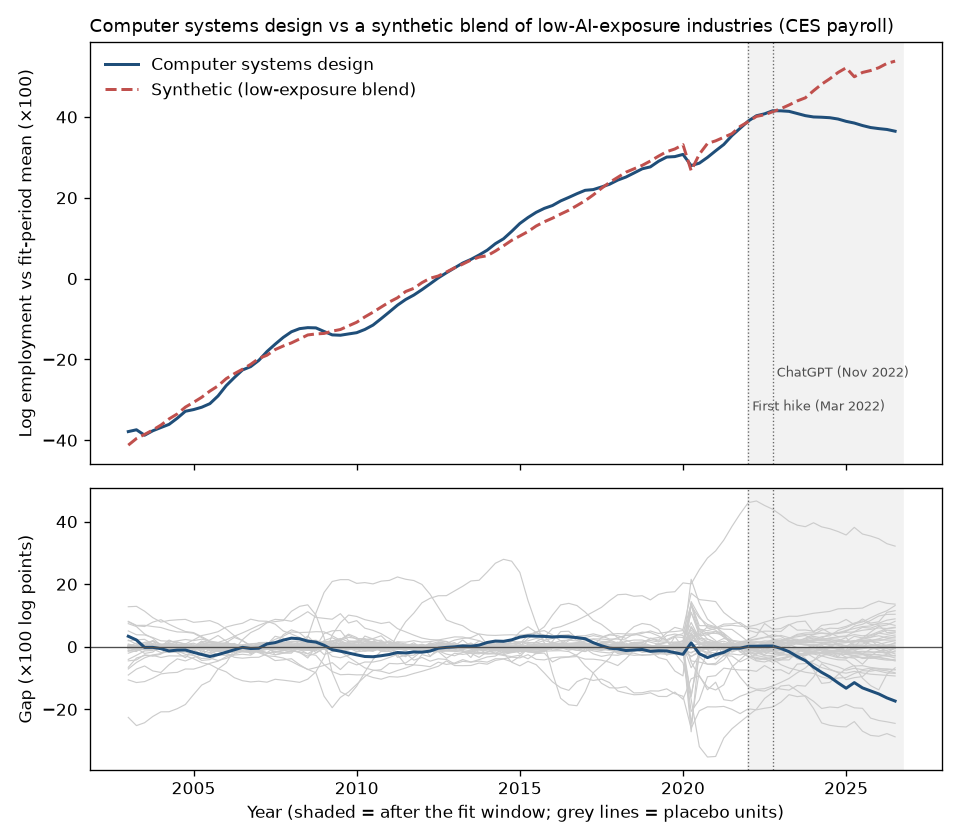

In [3]:
figure("fig_synth_industry_main")

## What it means

**Inconclusive.** The fit is excellent (hold-out error 0.6%) and tech ends about 13% below its twin by 2026, but
p ≈ 0.29: plenty of untreated industries drift that far from their own twins. With one treated unit, only effects of
about 16–20% stand out (the **minimum detectable effect**). **Decision that followed:** pool many industries
(synthetic DiD, notebook 3).

---
Code: `scripts/synth_industry.py`, `scripts/synth_variants.py` · All results: `docs/SCORECARD.md` · Every decision: `docs/DECISIONS.md` · The whole story: `README.md`